# Unsorted Rainbow Bars vs. Sorted Bars

**Family:** Bad vs. good &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Bad vs. good:* Common chart mistakes, each shown next to a better alternative that fixes it.

## Design purpose

Bars in alphabetical (or random) order, each in a different color, make the reader do the sorting in their head. The colors carry no information but suggest that they do, and vertical bars with long names force rotated, hard-to-read labels.

## When to use

- Sort nominal categories by value so ranking is immediate
- Use horizontal bars when category names are long
- Use one color for one series; add a second color only to highlight

## Avoid when

- Alphabetical ordering of categories that have no natural order
- Coloring each bar differently "to look nice"
- Rotated 45°/90° x-axis labels

## Alternatives

- Sorted horizontal bar chart
- Lollipop or Cleveland dot plot for many categories

## Design tips

- Keep natural orders (months, age bands, Likert levels) unsorted; sort everything else
- Put the value labels at the bar ends and lighten or drop the gridlines
- Use color to say something ("above target"), not to decorate

## Example

Average outpatient waiting time (minutes) for ten clinics.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(4)
clinics = ["Cardiology", "Dermatology", "Endocrinology", "Gastroenterology", "Hematology",
           "Nephrology", "Neurology", "Oncology", "Orthopedics", "Pulmonology"]
df = pd.DataFrame({"clinic": clinics, "wait_min": rng.uniform(12, 45, len(clinics)).round(0)})
TARGET = 30
df

,clinic,wait_min
0,Cardiology,43.0
1,Dermatology,29.0
2,Endocrinology,44.0
3,Gastroenterology,15.0
4,Hematology,32.0
5,Nephrology,24.0
6,Neurology,38.0
7,Oncology,18.0
8,Orthopedics,41.0
9,Pulmonology,30.0


### Plot

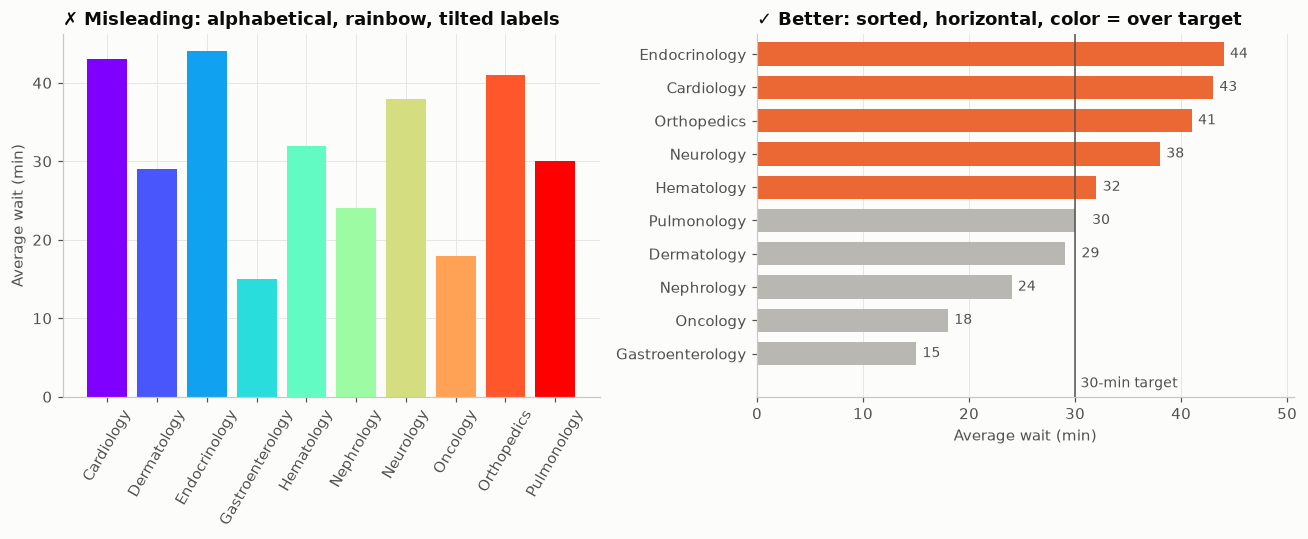

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Misleading: alphabetical, rainbow, rotated labels.
ax1.bar(df["clinic"], df["wait_min"], color=plt.get_cmap("rainbow")(np.linspace(0, 1, len(df))))
ax1.tick_params(axis="x", rotation=60)
ax1.set_ylabel("Average wait (min)")
ax1.set_title("✗ Misleading: alphabetical, rainbow, tilted labels", fontsize=11.5)

# Better: sorted, horizontal, one color + highlight for "over target".
d = df.sort_values("wait_min")
colors = np.where(d["wait_min"] > TARGET, PALETTE[1], GRAY)
ax2.barh(d["clinic"], d["wait_min"], color=colors, height=0.7)
ax2.axvline(TARGET, color="#52514e", linewidth=1)
ax2.text(TARGET + 0.5, -0.9, f"{TARGET}-min target", fontsize=9, color="#52514e", va="center")
ax2.set_ylim(-1.3, len(d) - 0.4)
for y, v in enumerate(d["wait_min"]):
    ax2.text(v + (1.6 if abs(v - TARGET) < 2 else 0.6), y, f"{v:.0f}", va="center", fontsize=9, color="#52514e")
ax2.set_xlabel("Average wait (min)")
ax2.set_xlim(0, d["wait_min"].max() * 1.15)
ax2.grid(axis="y", visible=False)
ax2.set_title("✓ Better: sorted, horizontal, color = over target", fontsize=11.5)
fig.tight_layout()
plt.show()

## How to read it

Find the clinic with the third-longest wait. On the left you scan back and forth and tilt your head; on the right it is the third bar from the top. The single color plus one highlight also tells you which clinics exceed the 30-minute target.

---
Standalone script: [`unsorted_bars.py`](unsorted_bars.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)